In [21]:
from numpy import random
import warnings
warnings.filterwarnings('ignore')
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


In [22]:
dataset = pd.read_csv('dataset.csv')
dataset

,timestamp,alpha,beta,delta,theta,gamma,arousal,valence,total_power,alpha_beta_ratio,theta_alpha_ratio,high_freq_ratio,frontal_alpha,parietal_alpha,temporal_beta,occipital_alpha,relaxation_index,attention_index,meditation_index,emotion
0,0,8.247225,9.423885,3.317986,6.848153,19.435433,0.607953,0.156294,47.620646,1.012549,0.700308,1.676683,8.022614,9.216866,7.198457,8.113871,1.001758,1.430617,0.529654,angry
1,1,15.740955,8.811577,4.340034,3.508749,19.090487,0.448033,0.571099,50.641114,1.757765,0.254667,2.287797,13.700040,11.093503,7.370500,13.830256,1.489487,2.276984,0.577979,excited
2,2,13.431451,18.928064,3.822576,8.073970,7.039027,0.909241,0.244801,48.817353,0.722878,0.595979,0.614908,11.195104,9.512846,19.830748,12.783523,0.575854,2.438770,1.448442,angry
3,3,10.858108,7.683628,1.487260,6.093926,23.090646,0.535689,0.304990,51.623056,1.255244,0.584000,3.256180,11.507738,12.460602,9.152181,9.166604,1.370618,1.419380,0.597654,happy
4,4,6.438594,9.425397,1.603746,3.685656,15.415629,0.914278,0.276102,38.198771,0.703721,0.580300,3.046505,6.530458,6.660719,10.081406,7.060187,0.716657,2.328471,0.388687,angry
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1995,11.860894,11.831078,3.647643,4.454917,23.422682,0.772868,0.418791,51.117699,1.014926,0.410851,2.613697,9.686101,11.308915,9.662922,11.633668,0.799273,2.541720,0.534304,happy
1996,1996,14.590192,9.062127,3.189840,4.053397,22.490682,0.577447,0.551513,50.889004,1.500779,0.285532,3.107628,16.469461,17.365688,9.887158,14.830137,1.647180,2.242087,0.773464,happy
1997,1997,5.642033,10.332078,3.900781,5.156196,25.146766,0.983730,0.036343,51.323617,0.544353,1.033053,2.505590,5.137535,5.667318,13.467848,6.758575,0.439032,2.087534,0.233148,angry
1998,1998,5.611278,12.889679,3.021238,7.731975,12.835816,1.026983,-0.139114,38.989049,0.447736,1.367540,1.152700,6.268343,4.987885,14.072374,5.995690,0.507887,1.918651,0.419952,angry


In [24]:
x_train=dataset.drop(['emotion','timestamp'],axis=1)
y_train=dataset[['emotion']]
le = LabelEncoder()
y_encoded = le.fit_transform(y_train)

X_train, X_test, Y_train, Y_test = train_test_split(x_train,y_encoded, test_size=0.20, random_state=42)


In [25]:
Xtest = np.array(X_test)
Xtest = np.reshape(Xtest, (Xtest.shape[0], Xtest.shape[1], 1))


In [26]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization
from keras.regularizers import l2
from keras.callbacks import EarlyStopping, LearningRateScheduler
from keras.callbacks import ModelCheckpoint, EarlyStopping, LearningRateScheduler
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
# Define early stopping and learning rate scheduler callbacks
initial_learning_rate = 0.001
def lr_schedule(epoch):
    return initial_learning_rate * (0.1 ** (epoch // 10))

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
lr_scheduler = LearningRateScheduler(lr_schedule)

# Define the rest of your callbacks
my_callbacks = [
    ModelCheckpoint(filepath='cnnlstm.h5', verbose=1, save_best_only=True, monitor='val_accuracy', mode='max'),
    early_stopping,
    lr_scheduler
]
model = Sequential()

# Add Convolutional and MaxPooling Layers with L2 Regularization
model.add(Conv1D(64, 3, padding="same", input_shape=(Xtest.shape[1], 1), activation='relu', kernel_regularizer=l2(0.01)))
model.add(Conv1D(64, 3, padding="same", activation='relu', kernel_regularizer=l2(0.01)))
model.add(MaxPooling1D(pool_size=2))
model.add(Conv1D(128, 3, padding="same", activation='relu', kernel_regularizer=l2(0.001)))
model.add(Conv1D(128, 3, padding="same", activation='relu', kernel_regularizer=l2(0.001)))
model.add(MaxPooling1D(pool_size=2))

# Add Batch Normalization
model.add(BatchNormalization())

# Add LSTM layer with L2 Regularization
model.add(LSTM(units=100, return_sequences=False, dropout=0.1, kernel_regularizer=l2(0.01)))
model.add(Dropout(0.5))  # Add dropout to reduce overfitting

# Add Dense layer with L2 Regularization
model.add(Dense(units=4, activation='softmax', kernel_regularizer=l2(0.01)))  # 4 classes with softmax activation

# Compile the model with a custom learning rate schedule
opt = Adam(learning_rate=initial_learning_rate)
model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])

model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_4 (Conv1D)           (None, 18, 64)            256       
                                                                 
 conv1d_5 (Conv1D)           (None, 18, 64)            12352     
                                                                 
 max_pooling1d_2 (MaxPooling  (None, 9, 64)            0         
 1D)                                                             
                                                                 
 conv1d_6 (Conv1D)           (None, 9, 128)            24704     
                                                                 
 conv1d_7 (Conv1D)           (None, 9, 128)            49280     
                                                                 
 max_pooling1d_3 (MaxPooling  (None, 4, 128)           0         
 1D)                                                  

In [27]:
model.load_weights('cnnlstm.h5')


In [28]:

Y_pred = model.predict(Xtest)


13/13 [==============================] - 1s 19ms/step


In [29]:
Y_pred_classes = np.argmax(Y_pred,axis = 1) 

In [31]:
Y_pred_classes

array([2, 0, 1, 1, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2,
       2, 2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 0, 2, 3, 2, 3, 0, 0, 0, 0, 2, 0,
       0, 2, 0, 0, 0, 0, 2, 2, 0, 1, 2, 2, 2, 0, 0, 2, 0, 1, 0, 2, 2, 0,
       0, 2, 0, 3, 0, 2, 2, 2, 1, 2, 2, 3, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 3, 0, 2, 0, 1, 0, 0, 0, 2, 1, 3,
       1, 1, 2, 0, 1, 2, 2, 0, 2, 3, 3, 0, 1, 0, 1, 3, 2, 2, 2, 1, 0, 2,
       0, 0, 2, 1, 1, 0, 2, 2, 1, 1, 0, 0, 0, 2, 2, 0, 2, 2, 0, 2, 0, 2,
       0, 2, 1, 1, 2, 2, 0, 0, 0, 3, 1, 1, 3, 2, 2, 2, 3, 2, 3, 2, 1, 2,
       0, 2, 0, 2, 0, 3, 0, 3, 1, 0, 3, 0, 0, 0, 0, 1, 3, 3, 3, 0, 2, 0,
       0, 1, 3, 2, 0, 2, 2, 0, 2, 2, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0, 0, 2,
       0, 2, 0, 1, 0, 2, 0, 0, 3, 0, 2, 0, 0, 0, 0, 0, 2, 0, 1, 0, 3, 2,
       0, 2, 2, 1, 3, 1, 2, 0, 2, 2, 0, 2, 3, 2, 2, 2, 0, 0, 0, 1, 0, 2,
       0, 1, 2, 2, 1, 2, 2, 0, 2, 0, 2, 1, 0, 0, 0, 2, 0, 0, 2, 2, 2, 0,
       3, 1, 2, 2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 2, 2,

In [30]:
Y_test

array([2, 0, 1, 1, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2,
       2, 2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 3, 2, 3, 2, 3, 0, 0, 0, 0, 2, 0,
       0, 2, 0, 0, 0, 0, 2, 2, 0, 1, 0, 2, 2, 0, 0, 2, 0, 1, 0, 2, 2, 0,
       0, 2, 0, 3, 0, 2, 2, 2, 2, 2, 2, 3, 0, 0, 2, 1, 0, 0, 0, 0, 0, 1,
       0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 3, 0, 2, 0, 1, 0, 0, 0, 2, 1, 1,
       1, 1, 2, 0, 1, 2, 2, 0, 2, 3, 3, 2, 1, 0, 1, 1, 2, 2, 2, 1, 0, 0,
       0, 2, 2, 1, 1, 0, 2, 2, 1, 1, 0, 0, 0, 2, 2, 2, 2, 2, 0, 2, 0, 2,
       0, 2, 1, 1, 2, 2, 0, 0, 0, 3, 1, 1, 3, 2, 2, 2, 3, 2, 3, 2, 1, 2,
       0, 2, 0, 2, 0, 1, 0, 3, 1, 0, 1, 0, 0, 0, 0, 1, 3, 3, 3, 0, 2, 0,
       0, 1, 3, 2, 0, 2, 2, 0, 2, 2, 0, 1, 2, 0, 1, 2, 0, 0, 0, 0, 0, 2,
       0, 2, 0, 1, 0, 2, 0, 0, 3, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 3, 2,
       0, 2, 2, 1, 1, 1, 2, 0, 2, 2, 2, 2, 3, 2, 0, 2, 0, 0, 0, 1, 0, 2,
       0, 1, 2, 2, 1, 1, 2, 0, 2, 0, 2, 1, 0, 0, 0, 2, 0, 0, 2, 2, 2, 0,
       3, 2, 2, 2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 2, 2,

In [32]:
Y_true=Y_test

In [33]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
        

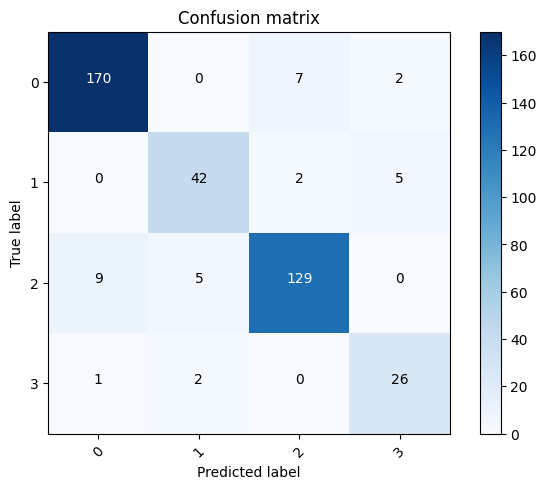

In [34]:
from sklearn.metrics import accuracy_score, precision_score, classification_report
from sklearn.metrics import confusion_matrix
import itertools
# compute the confusion matrix
confusion_mtx = confusion_matrix(Y_true, Y_pred_classes) 
# plot the confusion matrix
plot_confusion_matrix(confusion_mtx, classes = range(4))

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Assuming Y_true and Y_pred_classes are defined
# Y_true: Actual labels
# Y_pred_classes: Predicted labels

# Compute accuracy
accuracy = accuracy_score(Y_true, Y_pred_classes)
print("Accuracy:", accuracy)

# Compute precision
precision = precision_score(Y_true, Y_pred_classes, average='weighted')
print("Precision:", precision)

# Compute recall
recall = recall_score(Y_true, Y_pred_classes, average='weighted')
print("Recall:", recall)

# Compute F1-score
f1 = f1_score(Y_true, Y_pred_classes, average='weighted')
print("F1 Score:", f1)


Accuracy: 0.9175
Precision: 0.9189448836187967
Recall: 0.9175
F1 Score: 0.9178610417654623
